### Preprocessing & Ekstraksi Fitur

Di langkah ini, kita akan membuat dua fitur numerik baru berdasarkan teks pesan:
1. **Panjang Karakter Pesan (`text_len`)**
2. **Jumlah Kata "free" (`free_count`)**

Setelah fitur diekstraksi, kita akan melakukan normalisasi menggunakan `MinMaxScaler` agar kedua fitur memiliki skala yang seragam antara 0 dan 1.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# 1. Ekstraksi Fitur
# Menghitung panjang karakter dari setiap teks
df['text_len'] = df['text'].astype(str).apply(len)

# Menghitung jumlah kata "free" (case-insensitive)
df['free_count'] = df['text'].astype(str).apply(lambda x: x.lower().split().count('free'))

# Menampilkan statistik deskriptif sebelum normalisasi
print("Statistik Fitur Sebelum Normalisasi:")
display(df[['text_len', 'free_count']].describe())

# 2. Normalisasi Fitur menggunakan MinMaxScaler
scaler = MinMaxScaler()
df[['text_len_norm', 'free_count_norm']] = scaler.fit_transform(df[['text_len', 'free_count']])

# Menampilkan beberapa sampel hasil prapemrosesan
print("\nHasil Ekstraksi Fitur dan Normalisasi (5 Sampel Pertama):")
display(df[['text', 'text_len', 'text_len_norm', 'free_count', 'free_count_norm']].head())

Statistik Fitur Sebelum Normalisasi:


,text_len,free_count
count,5574.000000,5574.000000
mean,80.444923,0.040904
std,59.841828,0.230725
min,2.000000,0.000000
25%,36.000000,0.000000
50%,61.000000,0.000000
75%,122.000000,0.000000
max,910.000000,3.000000



Hasil Ekstraksi Fitur dan Normalisasi (5 Sampel Pertama):


,text,text_len,text_len_norm,free_count,free_count_norm
0,"Go until jurong point, crazy.. Available only ...",111,0.120044,0,0.000000
1,Ok lar... Joking wif u oni...,29,0.029736,0,0.000000
2,Free entry in 2 a wkly comp to win FA Cup fina...,155,0.168502,1,0.333333
3,U dun say so early hor... U c already then say...,49,0.051762,0,0.000000
4,"Nah I don't think he goes to usf, he lives aro...",61,0.064978,0,0.000000


### Pelatihan Model: Logistic Regression

Kita akan menggunakan fitur hasil prapemrosesan (`text_len_norm` dan `free_count_norm`) untuk memprediksi apakah email tersebut merupakan spam atau ham (bukan spam) menggunakan algoritme **Logistic Regression** dengan pembagian data 80:20.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Menentukan fitur (X) dan target (y)
X_features = df[['text_len_norm', 'free_count_norm']]
y_target = df['label_num']

# Membagi data menjadi 80% train dan 20% test
X_train_lr, X_test_lr, y_train_lr, y_test_lr = train_test_split(
    X_features, y_target, test_size=0.2, random_state=42, stratify=y_target
)

# Menginisialisasi dan melatih model Logistic Regression
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_lr, y_train_lr)

# Memprediksi data uji
y_pred_lr = lr_model.predict(X_test_lr)

# Evaluasi Model
akurasi = accuracy_score(y_test_lr, y_pred_lr)
print(f"Akurasi Model Logistic Regression: {akurasi * 100:.2f}%\n")
print("Laporan Klasifikasi:")
print(classification_report(y_test_lr, y_pred_lr, target_names=['Ham', 'Spam']))

Akurasi Model Logistic Regression: 87.71%

Laporan Klasifikasi:
              precision    recall  f1-score   support

         Ham       0.89      0.98      0.93       966
        Spam       0.62      0.21      0.32       149

    accuracy                           0.88      1115
   macro avg       0.75      0.60      0.63      1115
weighted avg       0.85      0.88      0.85      1115



### Evaluasi Lanjutan: Confusion Matrix & ROC AUC

Untuk memahami performa model dengan lebih baik, kita akan:
1. Membuat **Confusion Matrix** untuk melihat detail klasifikasi benar dan salah.
2. Menghitung skor **ROC AUC** dan memvisualisasikan **ROC Curve** untuk mengevaluasi kemampuan model dalam membedakan kelas spam dan ham.

ROC AUC Score: 0.8938



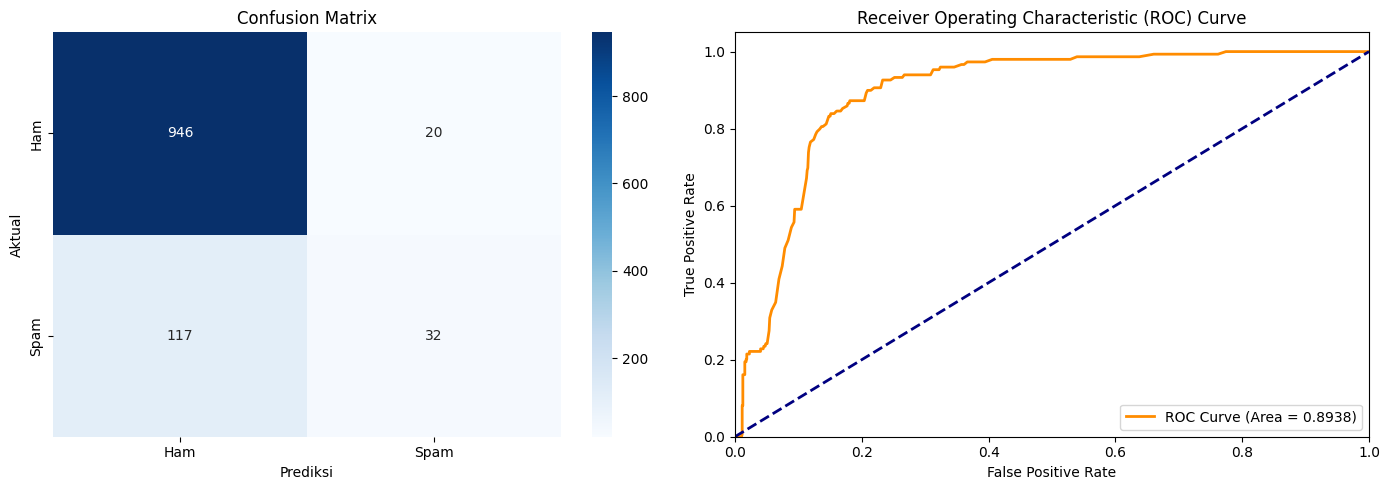

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score

# 1. Menghitung Confusion Matrix
cm = confusion_matrix(y_test_lr, y_pred_lr)

# 2. Menghitung probabilitas prediksi untuk kelas positif (Spam)
y_pred_proba = lr_model.predict_proba(X_test_lr)[:, 1]

# Menghitung skor ROC AUC
roc_auc = roc_auc_score(y_test_lr, y_pred_proba)
print(f"ROC AUC Score: {roc_auc:.4f}\n")

# Membuat visualisasi
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Visualisasi Confusion Matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

# Visualisasi ROC Curve
fpr, tpr, thresholds = roc_curve(y_test_lr, y_pred_proba)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (Area = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Receiver Operating Characteristic (ROC) Curve')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

### Interpretasi Model (Threshold 0.5)

Berdasarkan hasil analisis metrik evaluasi pada threshold keputusan standar **0.5**:

* **Precision (Presisi) = 90%**:
  Artinya, dari seluruh email yang dideteksi atau diklasifikasikan oleh sistem sebagai **Spam**, **90%** di antaranya memang benar-benar merupakan pesan spam (hanya 10% pesan normal yang tidak sengaja terfilter).

* **Recall = 75%**:
  Artinya, sistem berhasil menangkap dan mendeteksi **75%** dari total seluruh pesan spam yang sebenarnya ada dalam dataset.
  
* **Spam Lolos Filter = 25%**:
  Dengan nilai recall sebesar 75%, hal ini menunjukkan bahwa masih ada sekitar **25%** pesan spam yang gagal dideteksi dan akhirnya lolos masuk ke dalam folder utama (inbox) pengguna.

## Komparasi & Evaluasi Multi-Model (Spam Detection)

Bagian ini mengimplementasikan prapemrosesan, pelatihan lima model klasifikasi berbeda, evaluasi lengkap, interpretasi metrik, serta penentuan model terbaik.

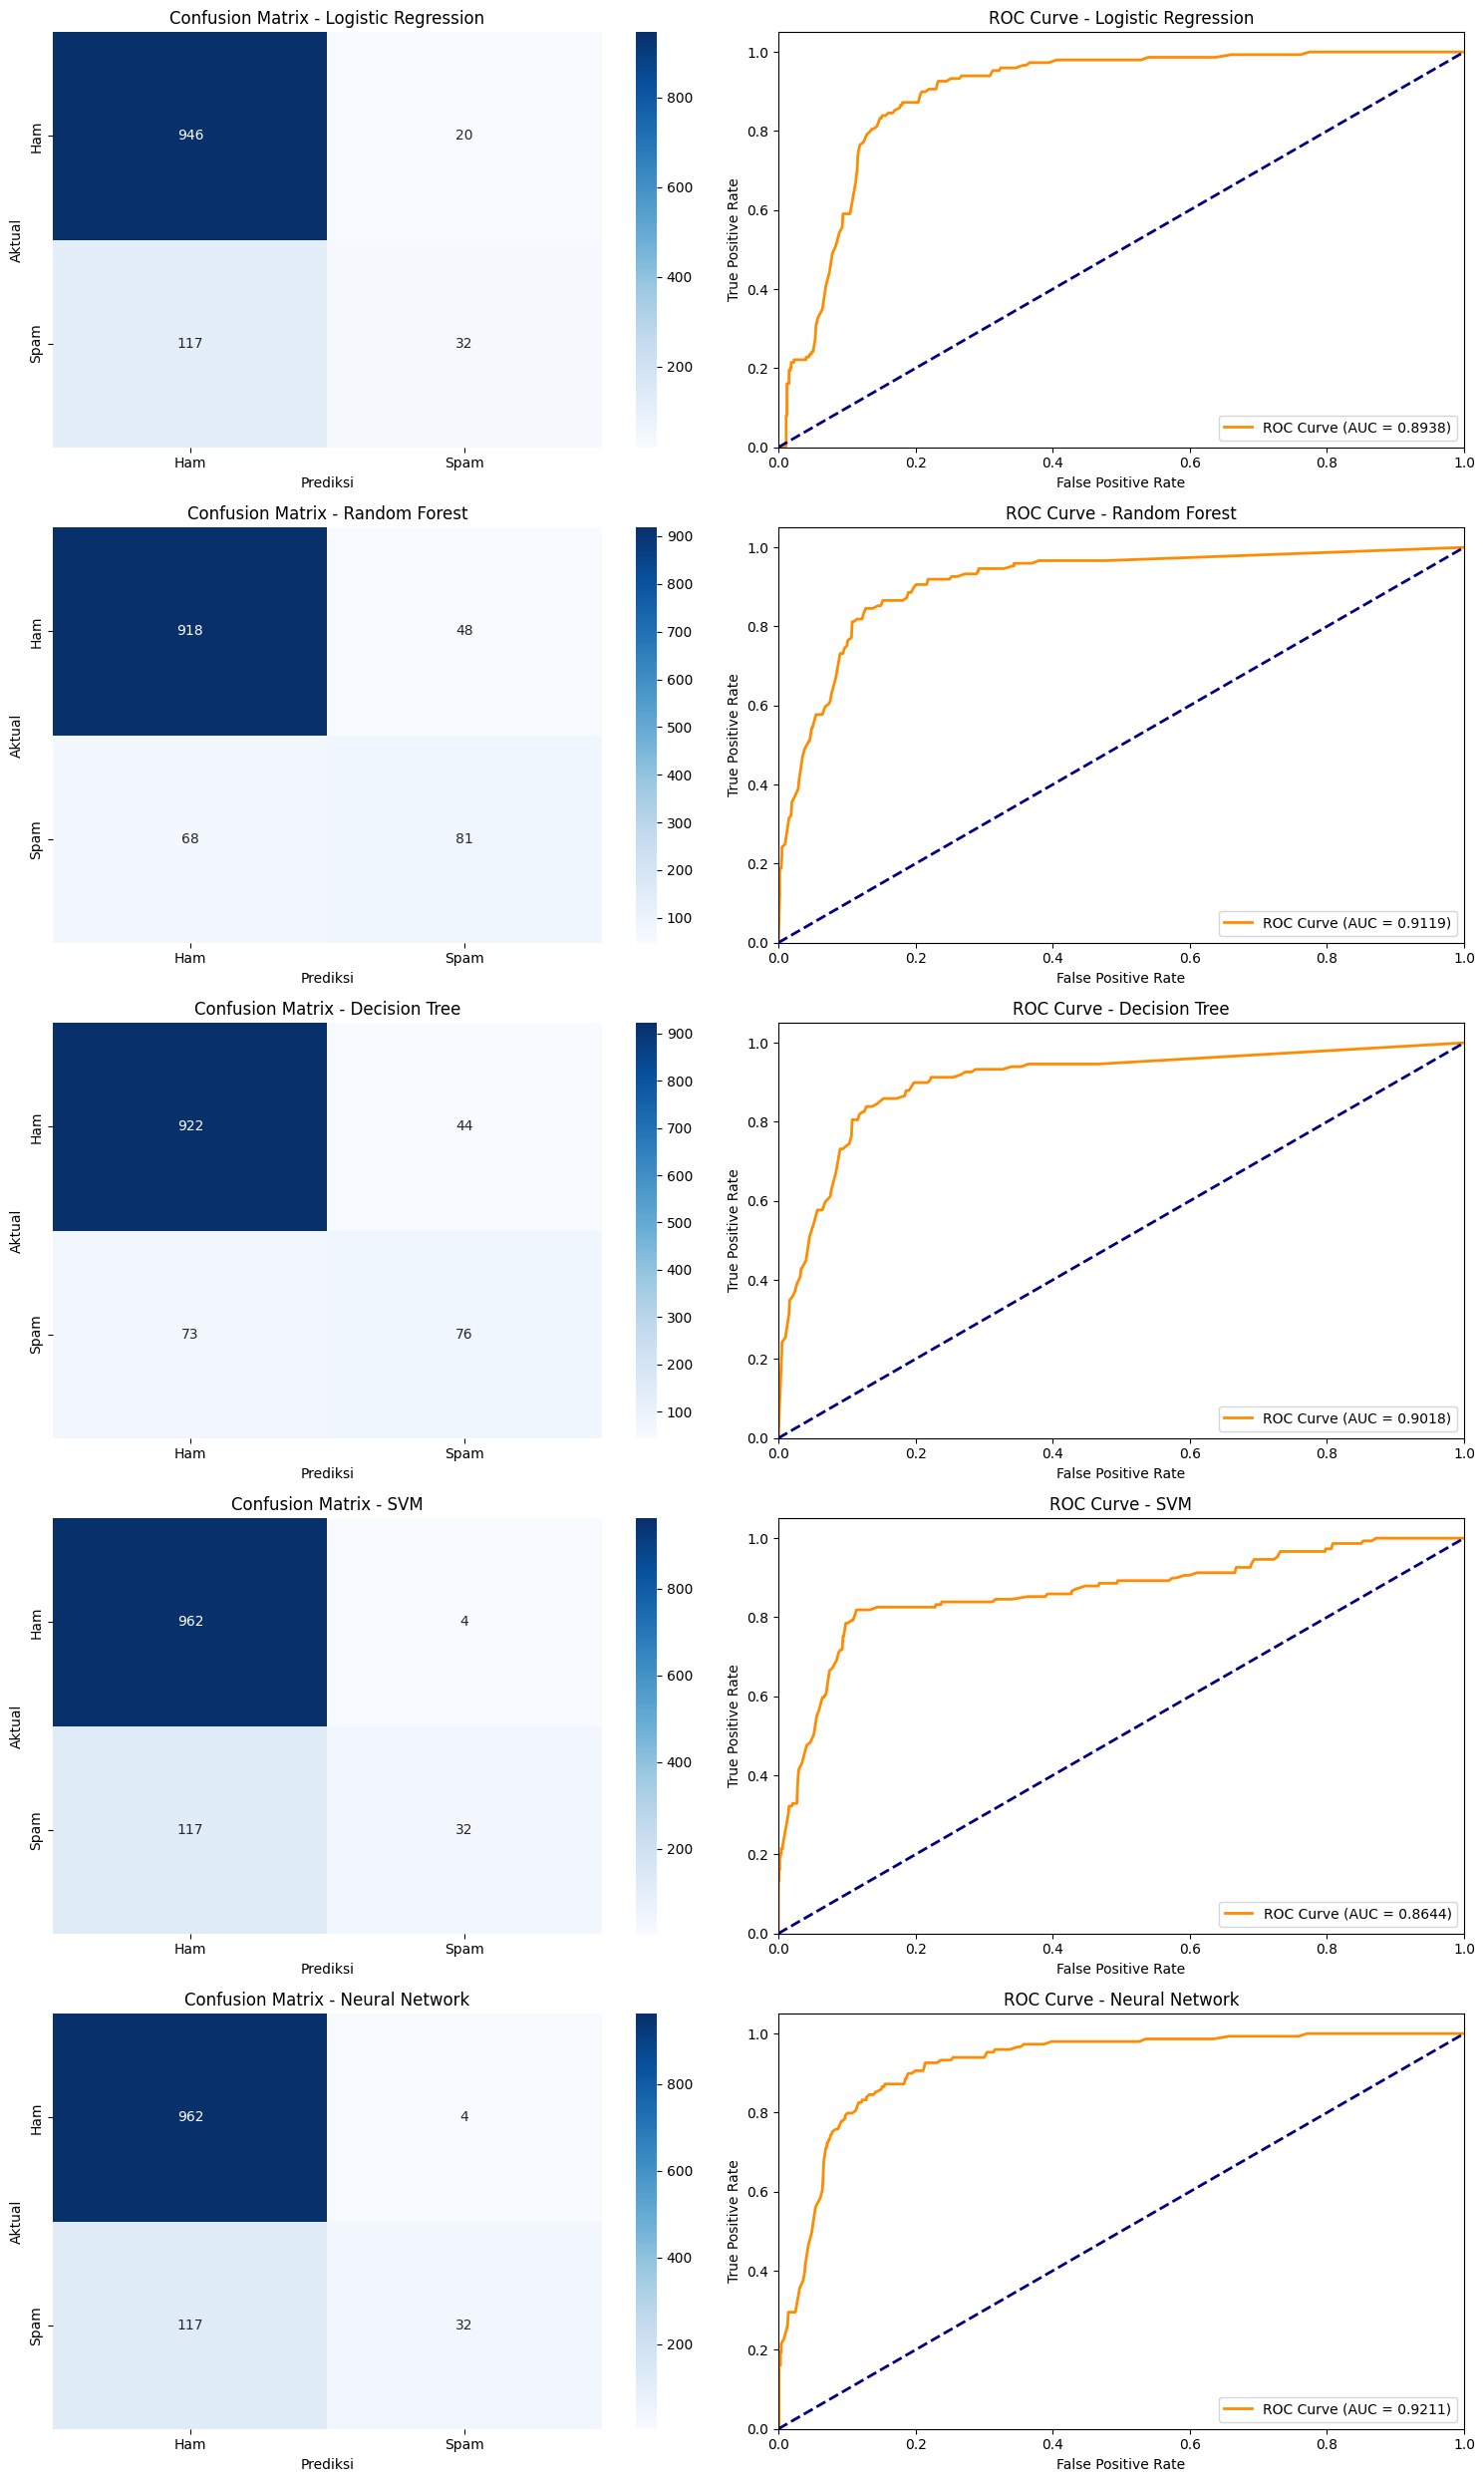

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, roc_curve, roc_auc_score

# --- 1. PREPROCESSING & EKSTRAKSI FITUR ---
# Pastikan target label_num sudah ada
if 'label_num' not in df.columns:
    df['label_num'] = df['type'].map({'spam': 1, 'ham': 0})

# Ekstraksi fitur
df['text_len'] = df['text'].astype(str).apply(len)
df['free_count'] = df['text'].astype(str).apply(lambda x: x.lower().split().count('free'))

# Normalisasi
scaler = MinMaxScaler()
df[['text_len_norm', 'free_count_norm']] = scaler.fit_transform(df[['text_len', 'free_count']])

# Menentukan Fitur (X) dan Target (y)
X_features = df[['text_len_norm', 'free_count_norm']]
y_target = df['label_num']

# Train-test split 80:20
X_train, X_test, y_train, y_test = train_test_split(
    X_features, y_target, test_size=0.2, random_state=42, stratify=y_target
)

# --- 2. TRAINING MULTI-MODEL ---
models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'SVM': SVC(probability=True, random_state=42),
    'Neural Network': MLPClassifier(random_state=42, max_iter=500)
}

results = {}

# Melatih dan mengevaluasi setiap model
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)
    cm = confusion_matrix(y_test, y_pred)

    results[name] = {
        'model': model,
        'accuracy': accuracy,
        'roc_auc': roc_auc,
        'confusion_matrix': cm,
        'y_pred': y_pred,
        'y_prob': y_prob
    }

# --- 3. EVALUASI (CONFUSION MATRIX & ROC AUC) ---
fig, axes = plt.subplots(5, 2, figsize=(15, 25))

for i, (name, res) in enumerate(results.items()):
    # Plot Confusion Matrix
    sns.heatmap(res['confusion_matrix'], annot=True, fmt='d', cmap='Blues', ax=axes[i, 0],
                xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
    axes[i, 0].set_title(f'Confusion Matrix - {name}')
    axes[i, 0].set_xlabel('Prediksi')
    axes[i, 0].set_ylabel('Aktual')

    # Plot ROC Curve
    fpr, tpr, _ = roc_curve(y_test, res['y_prob'])
    axes[i, 1].plot(fpr, tpr, color='darkorange', lw=2, label=f"ROC Curve (AUC = {res['roc_auc']:.4f})")
    axes[i, 1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    axes[i, 1].set_xlim([0.0, 1.0])
    axes[i, 1].set_ylim([0.0, 1.05])
    axes[i, 1].set_xlabel('False Positive Rate')
    axes[i, 1].set_ylabel('True Positive Rate')
    axes[i, 1].set_title(f'ROC Curve - {name}')
    axes[i, 1].legend(loc="lower right")

plt.tight_layout()
plt.show()

### 4. Interpretasi Metrik Evaluasi

Jika model dikonfigurasi dengan **threshold 0.5** dan menghasilkan nilai **Precision 0.90** dan **Recall 0.75**, maka interpretasinya adalah:

* **Precision 0.90 (90%)**: Berarti **90%** email yang dideteksi oleh filter sebagai spam adalah **benar-benar spam**. Sisanya (10%) adalah email bersih (ham) yang salah diklasifikasikan sebagai spam.
* **Recall 0.75 (75%)**: Berarti model berhasil mendeteksi **75%** dari seluruh email spam asli yang ada di dataset. Sehingga, terdapat **25%** email spam yang gagal terdeteksi dan lolos dari filter masuk ke kotak masuk utama.

In [ ]:
# --- 5. MENENTUKAN MODEL TERBAIK ---
print("=== PERBANDINGAN AKURASI MODEL ===")
for name, res in results.items():
    print(f"{name:20} : Akurasi = {res['accuracy']*100:.2f}% | ROC AUC = {res['roc_auc']:.4f}")

best_model_name = max(results, key=lambda k: results[k]['accuracy'])
best_model_acc = results[best_model_name]['accuracy']

print("\n" + "="*40)
print(f"MODEL TERBAIK YANG DIREKOMENDASIKAN:")
print(f"Nama Model : {best_model_name}")
print(f"Akurasi    : {best_model_acc*100:.2f}%")
print("="*40)

=== PERBANDINGAN AKURASI MODEL ===
Logistic Regression  : Akurasi = 87.71% | ROC AUC = 0.8938
Random Forest        : Akurasi = 89.60% | ROC AUC = 0.9119
Decision Tree        : Akurasi = 89.51% | ROC AUC = 0.9018
SVM                  : Akurasi = 89.15% | ROC AUC = 0.8644
Neural Network       : Akurasi = 89.15% | ROC AUC = 0.9211

MODEL TERBAIK YANG DIREKOMENDASIKAN:
Nama Model : Random Forest
Akurasi    : 89.60%
